In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("../data/processed/train.csv")

print("Training dataset shape:", train_df.shape)
print(train_df.head())

Training dataset shape: (13984, 21)
   url_length  n_dots  n_hypens  n_underline  n_slash  n_questionmark  \
0          51       3         1            0        4               0   
1          68       3         3            0        2               0   
2          67       2         0            0        7               0   
3          90       2         0            1        9               0   
4         194       2        10            0       12               0   

   n_equal  n_at  n_and  n_exclamation  ...  n_tilde  n_comma  n_plus  \
0        0     0      0              0  ...        0        0       0   
1        0     0      0              0  ...        0        0       0   
2        1     0      0              0  ...        0        0       0   
3        0     0      0              0  ...        0        0       0   
4        0     0      0              0  ...        0        0       0   

   n_asterisk  n_hastag  n_dollar  n_percent  n_redirection  count  phishing  
0      

In [2]:
class_counts = train_df["phishing"].value_counts().sort_index()

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print((class_counts / len(train_df) * 100).round(2))

Class counts:
phishing
0     2874
1    11110
Name: count, dtype: int64

Class percentages:
phishing
0    20.55
1    79.45
Name: count, dtype: float64


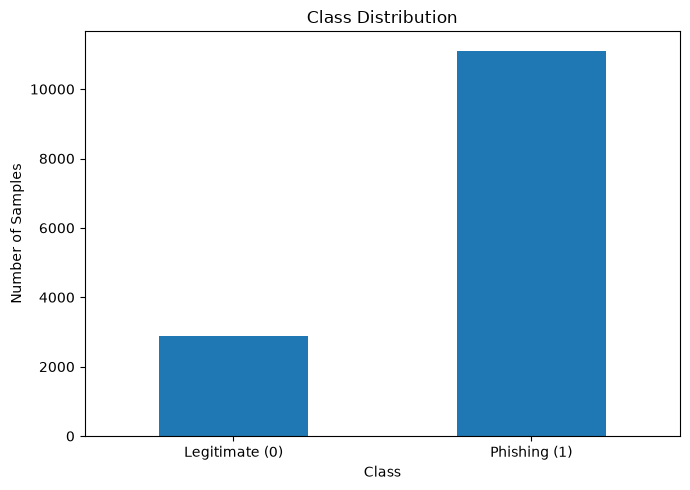

In [3]:
plt.figure(figsize=(7, 5))

class_counts.plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Legitimate (0)", "Phishing (1)"], rotation=0)

plt.tight_layout()
plt.show()

In [4]:
feature_columns = [col for col in train_df.columns if col != "phishing"]

feature_means = train_df.groupby("phishing")[feature_columns].mean().T

feature_means.columns = ["Legitimate", "Phishing"]

print(feature_means.round(3))

                Legitimate  Phishing
url_length          59.692    88.660
n_dots               2.485     3.065
n_hypens             2.434     1.114
n_underline          0.547     0.518
n_slash              1.171     3.081
n_questionmark       0.037     0.102
n_equal              0.271     0.911
n_at                 0.000     0.118
n_and                0.140     0.643
n_exclamation        0.008     0.011
n_space              0.045     0.017
n_tilde              0.010     0.016
n_comma              0.008     0.010
n_plus               0.026     0.006
n_asterisk           0.000     0.024
n_hastag             0.000     0.004
n_dollar             0.000     0.013
n_percent            0.523     0.347
n_redirection        0.766     0.370
count                1.000     1.120


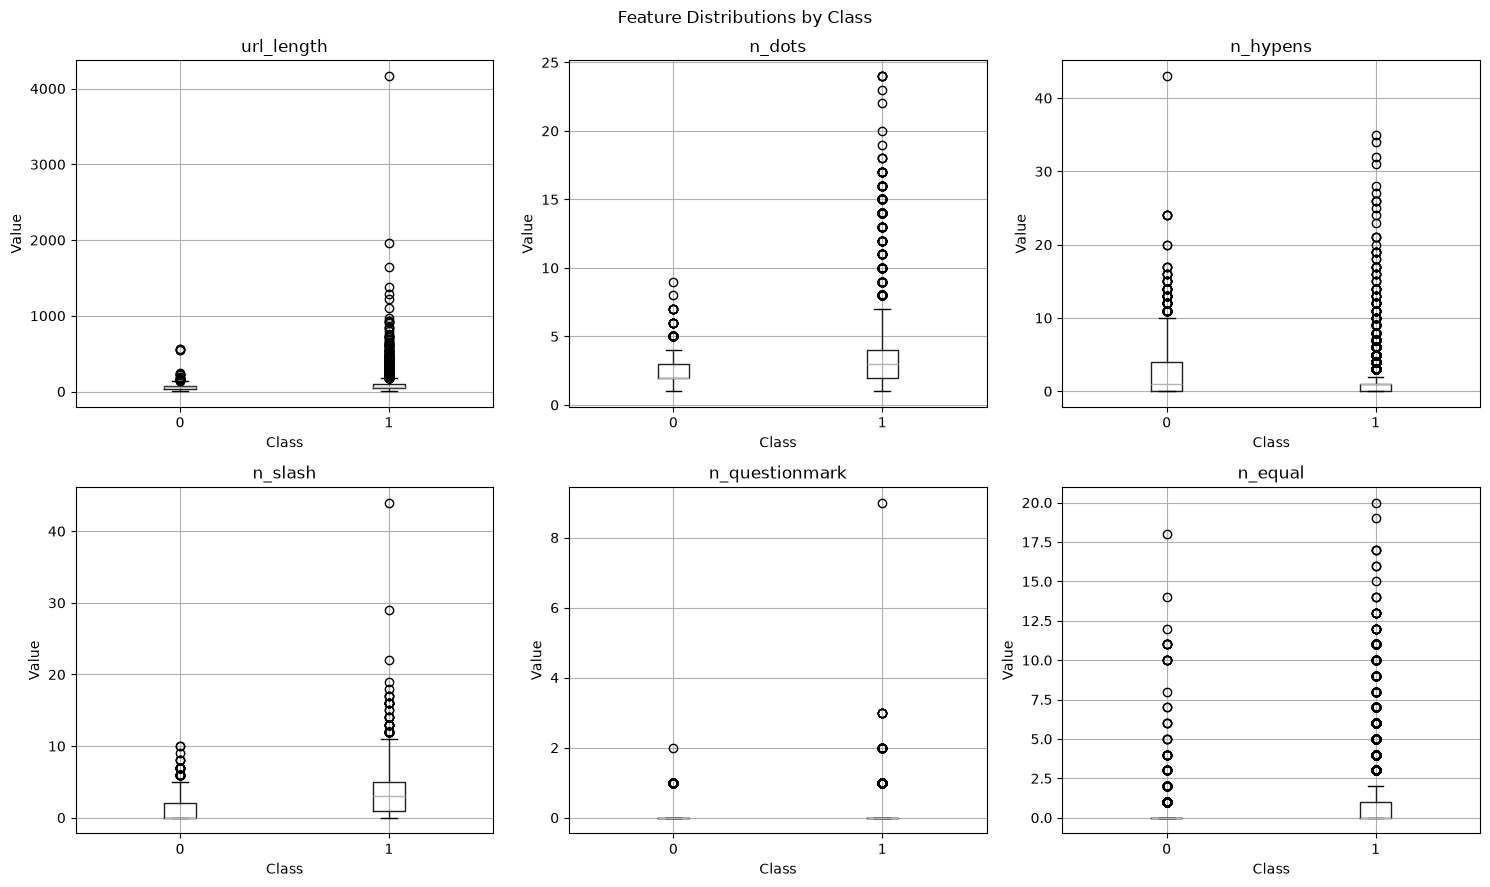

In [5]:
features_to_plot = [
    "url_length",
    "n_dots",
    "n_hypens",
    "n_slash",
    "n_questionmark",
    "n_equal"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features_to_plot):
    train_df.boxplot(
        column=feature,
        by="phishing",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("Value")

plt.suptitle("Feature Distributions by Class")
plt.tight_layout()
plt.show()